# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [3]:
import json


def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data["texts"]

texts = extract_texts_from_file('resources/data.json')
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [4]:
import re
import nltk

from nltk.stem import WordNetLemmatizer
from nltk.tokenize import TreebankWordTokenizer
from spellchecker import SpellChecker

In [10]:
def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    lemmatizer = WordNetLemmatizer()
    spell = SpellChecker()

    spell.word_frequency.load_words([
    "oppenheimer",
    "cillian",
    "kruskal",
    "dijkstra",
    "nolan",
    "delves"
])
    
    tokenizer = TreebankWordTokenizer()

    abbreviations = {
        "dr": "doctor",
        "mr": "mister",
        "mrs": "missus",
        "prof": "professor"
    }

    processed_texts = []

    for text in texts:
        text = text.lower()
        text = text.replace("’", "'")

        text = re.sub(r"\b([a-z])\.\s*(?=[a-z]\.)", r"\1", text)
        text = re.sub(r"\b([a-z])\.(?=\s|$)", r"\1", text)

        text = re.sub(r"\bit's\b", "it is", text)
        text = re.sub(r"\b([a-z]+)'s\b", r"\1", text)

        text = re.sub(r"[^a-z\s]", " ", text)

        words = tokenizer.tokenize(text)

        words = [abbreviations.get(word, word) for word in words]

        corrected_words = []
        for word in words:
            corrected = spell.correction(word)
            corrected_words.append(corrected if corrected else word)

        words = [
            word if word == "as"
            else lemmatizer.lemmatize(word, pos="v") if word == "delves"
            else lemmatizer.lemmatize(word)
            for word in corrected_words
        ]

        processed_texts.append(" ".join(words))

    return processed_texts

texts_processed = process_texts(texts)
print(texts_processed)

['oppenheimer directed by christopher nolan delve into the life of j robert oppenheimer the theoretical physicist who led the development of the atomic bomb the film explores his moral and emotional struggle', 'oppenheimer capture the life of the father of the atomic bomb and his internal conflict after the success of the manhattan project the film complex narrative reflects on the cost of scientific achievement', 'in oppenheimer cillian murphy delivers a riveting performance as the conflicted physicist who grapple with the consequence of his groundbreaking work on the atomic bomb under the weight of global politics and ethic', 'oppenheimer is a cinematic exploration of ambition guilt and responsibility through stunning visuals and a thought provoking story nolan brings the life of the brilliant but haunted physicist to the big screen', 'duck are versatile waterfowl known for their adaptability in freshwater and coastal habitat with webbed foot and waterproof feather they are excellent

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [12]:
def calcuate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    vectorizer = TfidfVectorizer()

    tfidf_matrix = vectorizer.fit_transform(texts_processed)

    cosine_matrix = cosine_similarity(tfidf_matrix)

    return cosine_matrix.tolist()

cosine_matrix = calcuate_tfidf(texts_processed)
print(cosine_matrix)

[[1.0000000000000004, 0.43097755553025585, 0.33641724348912533, 0.27444280732218457, 0.015527639757436573, 0.0643104200059647, 0.09123337450355712, 0.04287863819178431, 0.038429730786139336, 0.08098589920130995], [0.43097755553025585, 0.9999999999999998, 0.3564796427222846, 0.26319652711138225, 0.013991719903993463, 0.07934534118101808, 0.13640500543977815, 0.05022776093704314, 0.04650063765880138, 0.12420132831503644], [0.33641724348912533, 0.3564796427222846, 1.0, 0.1838198401283765, 0.05416057336296662, 0.052786374460325046, 0.1087012157652773, 0.04806651414589257, 0.08458366464483263, 0.08632385500802936], [0.27444280732218457, 0.26319652711138225, 0.1838198401283765, 0.9999999999999996, 0.054299219159867164, 0.1230659998743932, 0.09295220506323376, 0.09478541684775091, 0.055307690802644166, 0.07689831058795578], [0.015527639757436573, 0.013991719903993463, 0.05416057336296662, 0.054299219159867164, 0.9999999999999989, 0.06315064709740513, 0.1367675134628535, 0.04126494392811361, 0

In [15]:
import numpy as np
from gensim.models import Word2Vec

In [19]:
def calculate_word2vec_similarity(texts_processed):
    tokenized_texts = [text.split() for text in texts_processed]

    model = Word2Vec(
        sentences=tokenized_texts,
        vector_size=100,
        window=5,
        min_count=1,
        seed=42,
        workers=1
    )

    document_vectors = [
        np.mean([model.wv[word] for word in words], axis=0)
        for words in tokenized_texts
    ]

    return cosine_similarity(document_vectors).tolist()


word2vec_matrix = calculate_word2vec_similarity(texts_processed)
print(word2vec_matrix)

[[1.000000238418579, 0.7548891305923462, 0.5799185633659363, 0.5770564675331116, 0.3126383125782013, 0.24216265976428986, 0.29337117075920105, 0.31830236315727234, 0.16940847039222717, 0.4117315113544464], [0.7548891305923462, 0.9999998807907104, 0.648492693901062, 0.53007572889328, 0.15559567511081696, 0.2842664122581482, 0.25263842940330505, 0.10637232661247253, 0.12616489827632904, 0.4216691553592682], [0.5799185633659363, 0.648492693901062, 0.9999998211860657, 0.485186904668808, 0.21127252280712128, 0.09044581651687622, 0.24978700280189514, 0.07383540272712708, 0.08240591734647751, 0.22228984534740448], [0.5770564675331116, 0.53007572889328, 0.485186904668808, 1.0000001192092896, 0.32257935404777527, 0.2526838481426239, 0.2467372566461563, 0.18485261499881744, 0.29940661787986755, 0.3448704779148102], [0.3126383125782013, 0.15559567511081696, 0.21127252280712128, 0.32257935404777527, 0.9999999403953552, 0.29595986008644104, 0.3689899742603302, 0.1215677261352539, 0.3087947368621826

## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

In [20]:
import matplotlib.pyplot as plt

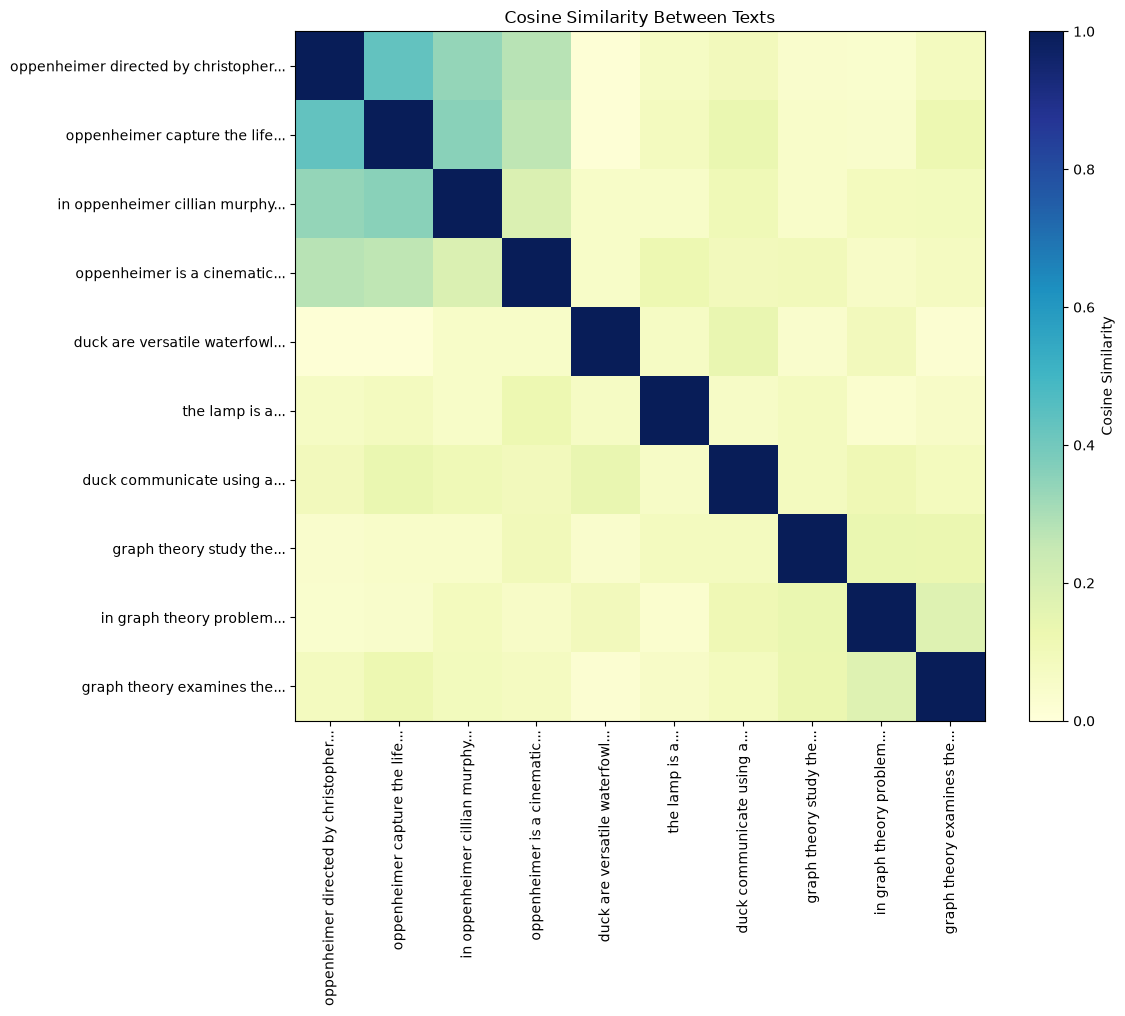

In [21]:
def visualize_data(cosine_matrix, texts_processed):
    """
    Visualize the cosine similarity matrix from the previous task. 

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    labels = [" ".join(text.split()[:4]) + "..."
              for text in texts_processed]

    plt.figure(figsize=(12, 10))

    plt.imshow(cosine_matrix, cmap="YlGnBu", vmin=0, vmax=1)
    plt.colorbar(label="Cosine Similarity")

    plt.xticks(range(len(labels)), labels, rotation=90)
    plt.yticks(range(len(labels)), labels)

    plt.title("Cosine Similarity Between Texts")
    plt.tight_layout()

    plt.show()

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

In [22]:
from sentence_transformers import SentenceTransformer

c:\Users\Olia\Desktop\Intelligent_Data_Analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3811.05it/s]


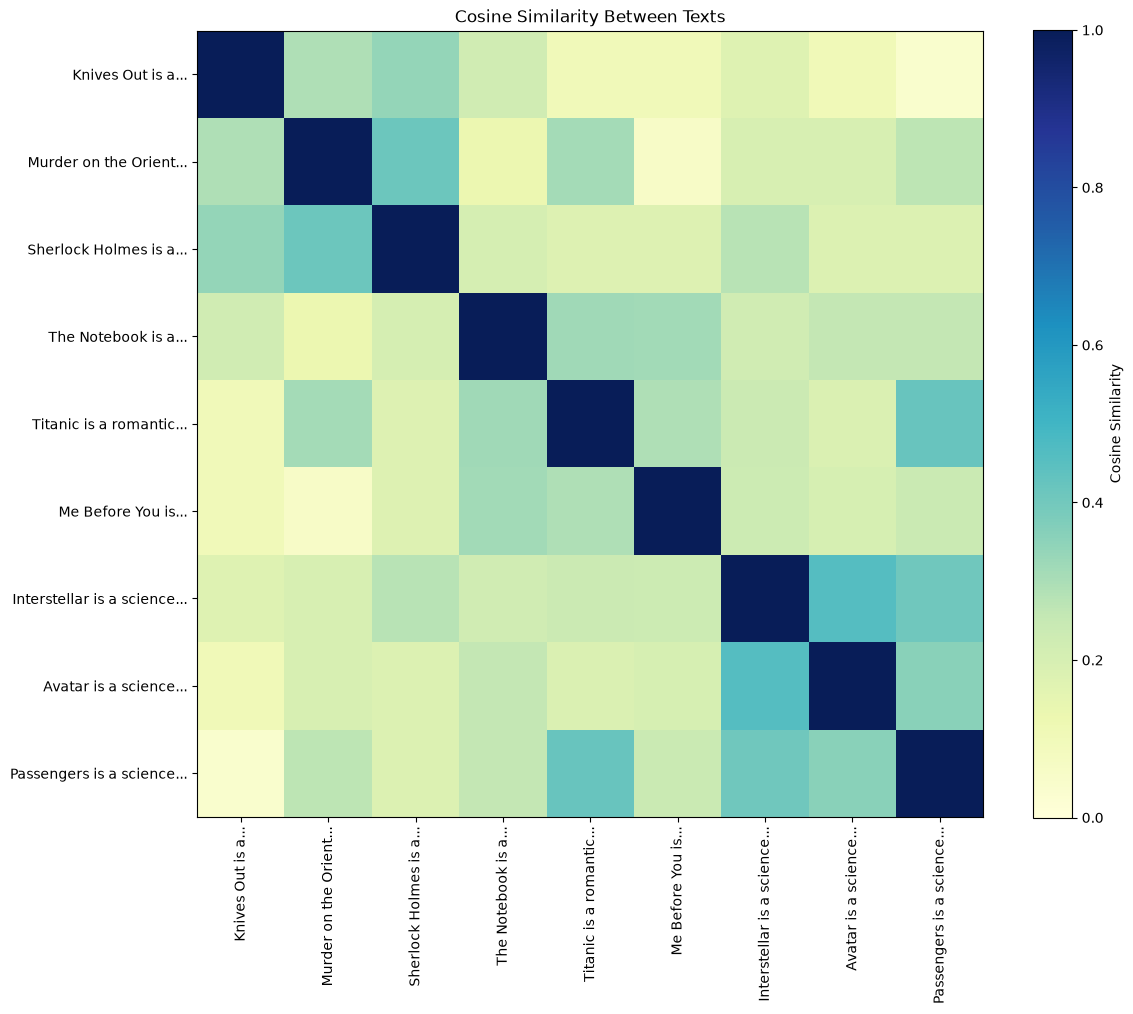

In [24]:
def get_texts():
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

    Args:
        None: None.

    Returns:
        list: list of texts.
    """
    return [
        "Knives Out is a mystery detective film about Benoit Blanc, a private detective who investigates the mysterious death of a wealthy novelist and questions his family to uncover the truth.",
        "Murder on the Orient Express is a detective mystery film about Hercule Poirot, who investigates the murder of a passenger aboard a luxury train where everyone is a suspect.",
        "Sherlock Holmes is a detective mystery film about a brilliant investigator and his partner Doctor Watson, who solve mysterious crimes and uncover a dangerous conspiracy in London.",

        "The Notebook is a romantic drama about Noah and Allie, two young lovers from different social backgrounds who struggle to stay together despite family opposition.",
        "Titanic is a romantic drama about Jack and Rose, two people from different social classes who fall in love aboard a luxury ship facing a tragic disaster.",
        "Me Before You is a romantic drama about Louisa, a young woman who develops a deep emotional relationship with Will, a wealthy man living with a disability.",

        "Interstellar is a science fiction film about astronauts traveling through a wormhole to search for a habitable planet and save humanity from extinction.",
        "Avatar is a science fiction film about a human who travels to the alien planet Pandora and becomes involved in a conflict between humans and its native inhabitants.",
        "Passengers is a science fiction romance film about two passengers who wake up early from hibernation aboard a spaceship traveling to a distant planet."
    ]



texts = get_texts()

model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = model.encode(texts)

cosine_matrix = cosine_similarity(embeddings)

visualize_data(cosine_matrix, texts)